# Simple Linear Regression
**IBM Machine Learning with Python Lab**

Estimated time needed: **15 minutes**

---

### Objectives
After completing this lab, you will be able to:
- Understand the core concepts of Simple Linear Regression ($y = \theta_0 + \theta_1 x$).
- Use `scikit-learn` to implement, train, and test a linear regression model on real data.
- Split data into Training (80%) and Testing (20%) sets to evaluate out-of-sample accuracy.
- Evaluate model performance using standard regression metrics: **MAE**, **MSE**, and **R2-Score**.
- Solve the lab practice exercise and understand why `FUELCONSUMPTION_COMB` produces a lower Mean Squared Error than `ENGINESIZE`.

---

### Understanding the Data
The dataset `FuelConsumptionCo2.csv` contains model-specific fuel consumption ratings and estimated carbon dioxide emissions for new light-duty vehicles for retail sale in Canada:
- **MODELYEAR**: e.g., 2014
- **MAKE**: e.g., Acura, Chevrolet, Ford
- **MODEL**: e.g., ILX, Cruze, Focus
- **VEHICLECLASS**: e.g., Compact, SUV, Mid-size
- **ENGINESIZE**: Engine size in liters (e.g., 2.0, 3.5, 4.0)
- **CYLINDERS**: Number of cylinders (e.g., 4, 6, 8)
- **TRANSMISSION**: Transmission type (e.g., A6, AS6, M6)
- **FUELTYPE**: Fuel type (Z = Premium Gasoline, X = Regular Gasoline, D = Diesel, E = Ethanol)
- **FUELCONSUMPTION_CITY**: City fuel consumption (L/100 km)
- **FUELCONSUMPTION_HWY**: Highway fuel consumption (L/100 km)
- **FUELCONSUMPTION_COMB**: Combined fuel consumption city + highway (L/100 km)
- **CO2EMISSIONS**: Carbon dioxide emissions in grams per kilometer (target variable $y$)


## 1. Importing Needed Packages

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
%matplotlib inline

## 2. Downloading and Reading the Data
We load the dataset directly from IBM Cloud Object Storage into a Pandas DataFrame.

In [8]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"
df = pd.read_csv(url)

# Display the first 5 rows
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


## 3. Data Exploration
Let's first take a look at the descriptive statistics of the numerical features using `df.describe()`.

In [9]:
# Summary statistics of all numerical columns
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


### Selecting Features
Let's select a subset of features to explore more closely: `ENGINESIZE`, `CYLINDERS`, `FUELCONSUMPTION_COMB`, and `CO2EMISSIONS`.

In [10]:
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244
5,3.5,6,10.0,230
6,3.5,6,10.1,232
7,3.7,6,11.1,255
8,3.7,6,11.6,267


### Visualizing Feature Distributions (Histograms)
We can plot histograms of each feature to inspect their distributions.

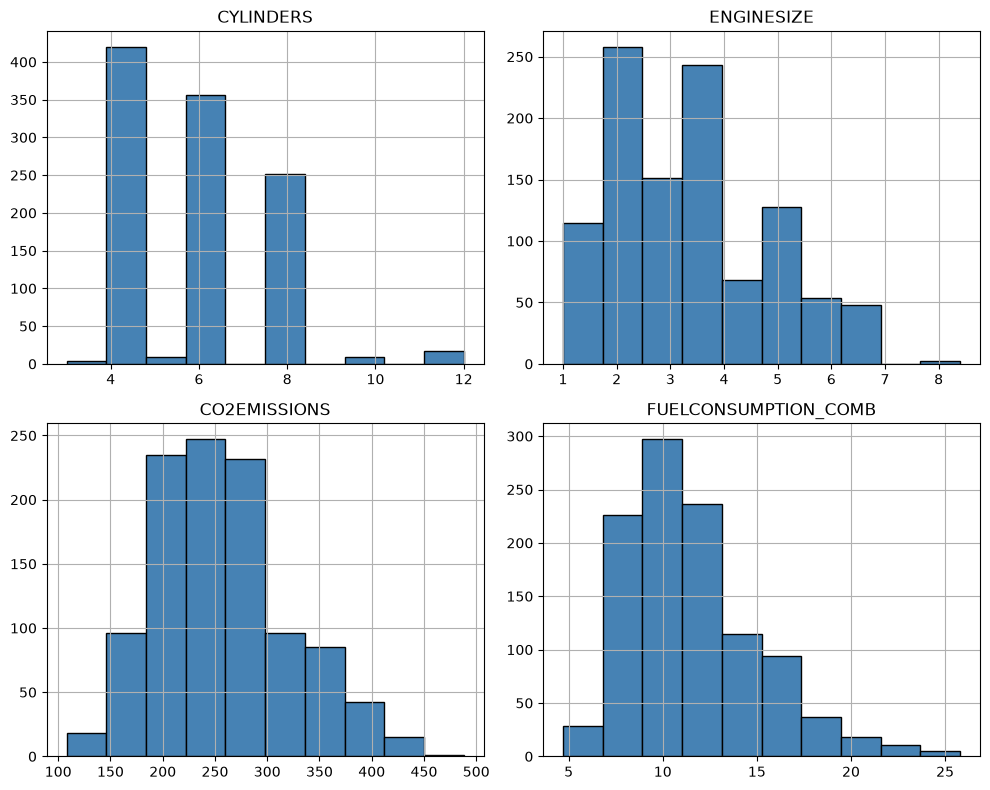

In [11]:
viz = cdf[['CYLINDERS','ENGINESIZE','CO2EMISSIONS','FUELCONSUMPTION_COMB']]
viz.hist(figsize=(10, 8), color='steelblue', edgecolor='black')
plt.tight_layout()
plt.show()

### Plotting Features vs. Emission
Now, let's plot scatter plots of these features against `CO2EMISSIONS` to see how linear their relationships are.

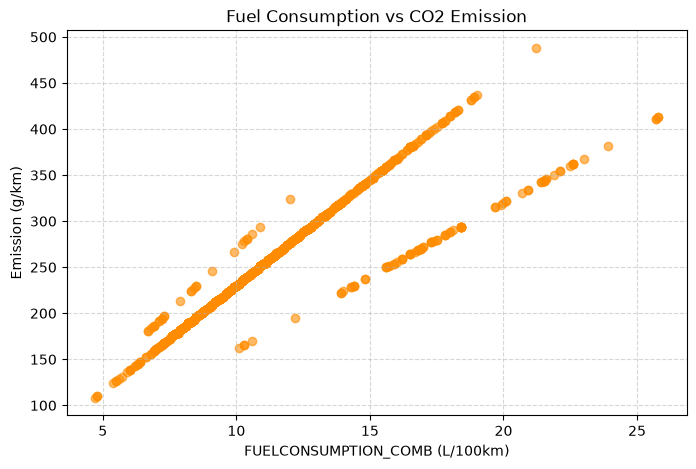

In [12]:
# 1. FUELCONSUMPTION_COMB vs CO2EMISSIONS
plt.figure(figsize=(8, 5))
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS, color='darkorange', alpha=0.6)
plt.xlabel("FUELCONSUMPTION_COMB (L/100km)")
plt.ylabel("Emission (g/km)")
plt.title("Fuel Consumption vs CO2 Emission")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

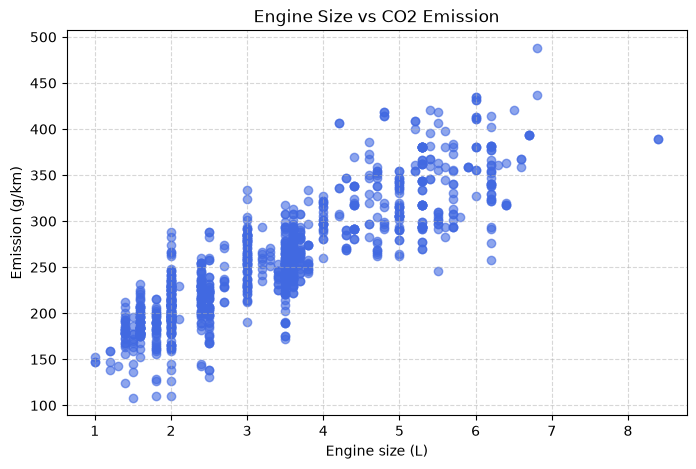

In [13]:
# 2. ENGINESIZE vs CO2EMISSIONS
plt.figure(figsize=(8, 5))
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color='royalblue', alpha=0.6)
plt.xlabel("Engine size (L)")
plt.ylabel("Emission (g/km)")
plt.title("Engine Size vs CO2 Emission")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Practice Plot: Cylinders vs Emission
Plot `CYLINDERS` against `CO2EMISSIONS` to check its linearity.

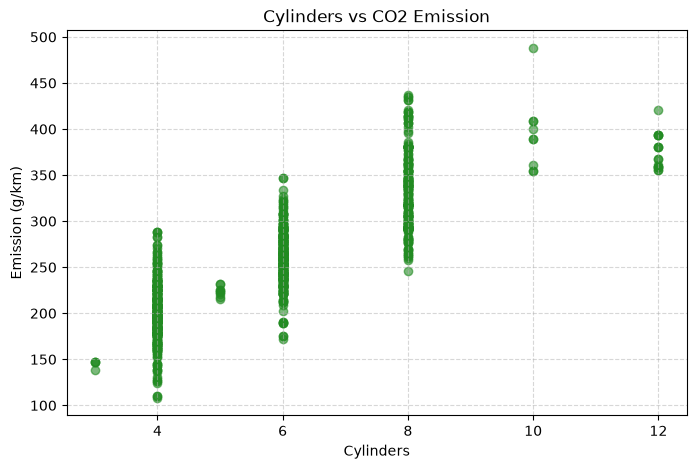

In [14]:
# 3. CYLINDERS vs CO2EMISSIONS
plt.figure(figsize=(8, 5))
plt.scatter(cdf.CYLINDERS, cdf.CO2EMISSIONS, color='forestgreen', alpha=0.6)
plt.xlabel("Cylinders")
plt.ylabel("Emission (g/km)")
plt.title("Cylinders vs CO2 Emission")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 4. Creating Train and Test Dataset

Train/Test Split involves splitting the dataset into mutually exclusive training and testing sets.
- **Training Set (~80%)**: Used to fit the regression model and determine the optimal parameters $\theta_0$ (intercept) and $\theta_1$ (slope).
- **Testing Set (~20%)**: Held out during training and used exclusively to evaluate out-of-sample accuracy. This provides a more realistic evaluation of how well the model generalizes to new data.

We set a random seed (`np.random.seed(42)`) to ensure exact reproducibility across runs.

In [15]:
np.random.seed(42)

msk = np.random.rand(len(df)) < 0.8
train = cdf[msk]
test = cdf[~msk]

print(f"Total rows:    {len(df)}")
print(f"Train rows:    {len(train)} ({len(train)/len(df)*100:.1f}%)")
print(f"Test rows:     {len(test)} ({len(test)/len(df)*100:.1f}%)")

Total rows:    1067
Train rows:    848 (79.5%)
Test rows:     219 (20.5%)


## 5. Simple Regression Model: Training with `ENGINESIZE`

Linear Regression fits a linear model with coefficients $\theta = (\theta_0, \theta_1)$ to minimize the residual sum of squares between the observed targets $y$ and the targets predicted by the linear approximation $\hat{y}$:
$$y = \theta_0 + \theta_1 x$$
Where:
- $y$ = `CO2EMISSIONS` (dependent variable / target)
- $x$ = `ENGINESIZE` (independent variable / feature)
- $\theta_0$ = Intercept (`regr.intercept_`)
- $\theta_1$ = Coefficient / Slope (`regr.coef_`)

**Note on 2D Arrays in Scikit-Learn:**
`scikit-learn` requires feature matrices $X$ to have 2 dimensions: `(n_samples, n_features)`.
Therefore, we extract features using double brackets `train[['ENGINESIZE']]` or `np.asanyarray(...)`, producing shape `(N, 1)` rather than `(N,)`.

In [16]:
from sklearn import linear_model

# Initialize the Linear Regression model
regr = linear_model.LinearRegression()

# Prepare 2D arrays for features and target
train_x = np.asanyarray(train[['ENGINESIZE']])
train_y = np.asanyarray(train[['CO2EMISSIONS']])

# Train the model (fit ordinary least squares)
regr.fit(train_x, train_y)

# Print the fitted parameters
print("Coefficients (θ1 / Slope):", regr.coef_[0][0])
print("Intercept (θ0):           ", regr.intercept_[0])
print(f"\nFitted Equation: CO2EMISSIONS = {regr.intercept_[0]:.2f} + {regr.coef_[0][0]:.2f} * ENGINESIZE")

Coefficients (θ1 / Slope): 39.526117997300126
Intercept (θ0):            124.17604843641709

Fitted Equation: CO2EMISSIONS = 124.18 + 39.53 * ENGINESIZE


### Plotting the Regression Line
We plot the fitted regression line over the training data points to visually inspect the fit.

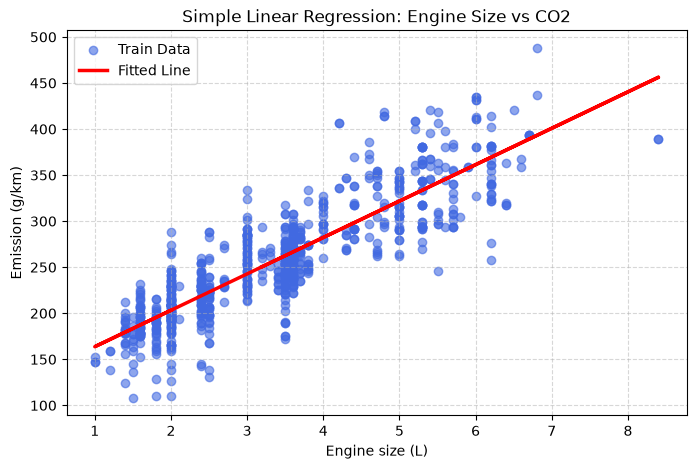

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(train.ENGINESIZE, train.CO2EMISSIONS, color='royalblue', alpha=0.6, label='Train Data')
plt.plot(train_x, regr.intercept_[0] + regr.coef_[0][0] * train_x, '-r', linewidth=2.5, label='Fitted Line')
plt.xlabel("Engine size (L)")
plt.ylabel("Emission (g/km)")
plt.title("Simple Linear Regression: Engine Size vs CO2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Model 1 Evaluation on Test Data

We calculate three standard regression metrics to quantify prediction accuracy on the test set:
1. **Mean Absolute Error (MAE)**: $\frac{1}{n} \sum |y - \hat{y}|$
2. **Mean Squared Error (MSE)** / Residual Sum of Squares: $\frac{1}{n} \sum (y - \hat{y})^2$
3. **R2-Score**: Coefficient of Determination ($1 - \frac{SS_{res}}{SS_{tot}}$), measuring the proportion of variance explained by the model.

In [12]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Prepare test data
test_x = np.asanyarray(test[['ENGINESIZE']])
test_y = np.asanyarray(test[['CO2EMISSIONS']])

# Make predictions on test set
test_y_ = regr.predict(test_x)

# Calculate metrics
mae_engine = mean_absolute_error(test_y, test_y_)
mse_engine = mean_squared_error(test_y, test_y_)
r2_engine = r2_score(test_y, test_y_)

print("--- Model 1 (ENGINESIZE) Evaluation ---")
print("Mean Absolute Error (MAE): %.2f" % mae_engine)
print("Residual sum of squares (MSE): %.2f" % mse_engine)
print("R2-score:                 %.4f" % r2_engine)

--- Model 1 (ENGINESIZE) Evaluation ---
Mean Absolute Error (MAE): 22.58
Residual sum of squares (MSE): 851.05
R2-score:                 0.7782


---
## 6. Practice: Training with `FUELCONSUMPTION_COMB`

Let's see what the evaluation metrics are if we train a regression model using the `FUELCONSUMPTION_COMB` feature instead of `ENGINESIZE`.

### Step 1 & 2: Feature Selection (2D Array)
Select `FUELCONSUMPTION_COMB` as `train_x` from the `train` dataframe and `test_x` from the `test` dataframe.
Double brackets `[['FUELCONSUMPTION_COMB']]` preserve the required 2D structure `(N, 1)`.

In [13]:
train_x = train[["FUELCONSUMPTION_COMB"]]
test_x = test[["FUELCONSUMPTION_COMB"]]

print("train_x shape:", train_x.shape)
print("test_x shape: ", test_x.shape)

train_x shape: (848, 1)
test_x shape:  (219, 1)


### Step 3: Train a Linear Regression Model
**Prompt**:
> Train a linear regression model using the training data you created. Remember to transform your 1D feature into a 2D array.
>
> `regr = linear_model.# ADD CODE`
> `# ADD CODE`

**Solution**:
```python
regr = linear_model.LinearRegression()
regr.fit(train_x, train_y)
```

### Step 4: Make Predictions on Testing Data
**Prompt**:
> Use the model to make test predictions on the fuel consumption testing data.
>
> `y = # ADD CODE`

**Solution**:
```python
y = regr.predict(test_x)
```

### Step 5: Calculate and Print Mean Squared Error
**Prompt**:
> Calculate and print the Mean Squared Error of the test predictions.
>
> `# ADD CODE`

**Solution**:
```python
print("Mean Squared Error (MSE) : %.2f" % np.mean((y - test_y) ** 2))
# Or using scikit-learn:
# print("MSE : %.2f" % mean_squared_error(test_y, y))
```

In [14]:
# 3. Train a linear regression model using the training data created
regr = linear_model.LinearRegression()
regr.fit(train_x, train_y)

print("Coefficients (θ1):", regr.coef_[0][0])
print("Intercept (θ0):   ", regr.intercept_[0])
print(f"Fitted Equation: CO2EMISSIONS = {regr.intercept_[0]:.2f} + {regr.coef_[0][0]:.2f} * FUELCONSUMPTION_COMB")

# 4. Use the model to make test predictions on the fuel consumption testing data
y = regr.predict(test_x)

# 5. Calculate and print the Mean Squared Error of the test predictions
mse_fuel_np = np.mean((y - test_y) ** 2)
print("\nMean Squared Error (via np.mean): %.2f" % mse_fuel_np)

mse_fuel_sklearn = mean_squared_error(test_y, y)
mae_fuel = mean_absolute_error(test_y, y)
r2_fuel = r2_score(test_y, y)

print("Mean Squared Error (via sklearn): %.2f" % mse_fuel_sklearn)
print("Mean Absolute Error (MAE):        %.2f" % mae_fuel)
print("R2-score:                         %.4f" % r2_fuel)

Coefficients (θ1): 16.253443785741638
Intercept (θ0):    68.1003497855315
Fitted Equation: CO2EMISSIONS = 68.10 + 16.25 * FUELCONSUMPTION_COMB

Mean Squared Error (via np.mean): 772.59
Mean Squared Error (via sklearn): 772.59
Mean Absolute Error (MAE):        20.41
R2-score:                         0.7986


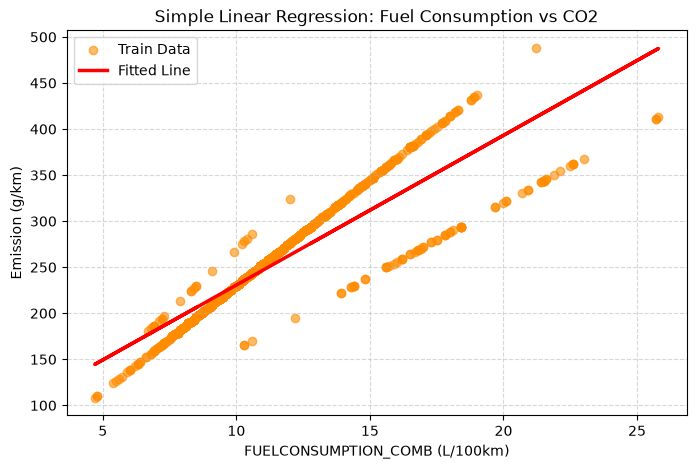

In [15]:
# Plotting the regression line for FUELCONSUMPTION_COMB
plt.figure(figsize=(8, 5))
plt.scatter(train.FUELCONSUMPTION_COMB, train.CO2EMISSIONS, color='darkorange', alpha=0.6, label='Train Data')
plt.plot(train_x, regr.intercept_[0] + regr.coef_[0][0] * train_x, '-r', linewidth=2.5, label='Fitted Line')
plt.xlabel("FUELCONSUMPTION_COMB (L/100km)")
plt.ylabel("Emission (g/km)")
plt.title("Simple Linear Regression: Fuel Consumption vs CO2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 7. Model Comparison and Conclusion

Let's compare the test evaluation metrics side by side:

In [16]:
comparison_df = pd.DataFrame({
    'Feature': ['ENGINESIZE', 'FUELCONSUMPTION_COMB'],
    'MAE (Lower is better)': [mae_engine, mae_fuel],
    'MSE (Lower is better)': [mse_engine, mse_fuel_sklearn],
    'R2-Score (Higher is better)': [r2_engine, r2_fuel]
})

comparison_df.round(2)

,Feature,MAE (Lower is better),MSE (Lower is better),R2-Score (Higher is better)
0,ENGINESIZE,22.58,851.05,0.78
1,FUELCONSUMPTION_COMB,20.41,772.59,0.80


### Why is the MSE smaller when we train using `FUELCONSUMPTION_COMB` rather than `ENGINESIZE`?

As noted in the lab conclusion:
> *"As you might expect from your exploratory analysis, the MSE is smaller when we train using FUELCONSUMPTION_COMB rather than ENGINESIZE."*

**Physical and Statistical Explanation:**
1. **Direct Chemical Mechanism:**
   Carbon dioxide ($CO_2$) is a direct chemical product of the combustion reaction:
   $$\text{Hydrocarbon Fuel} + O_2 \longrightarrow CO_2 + H_2O + \text{Energy}$$
   Every liter of fuel combusted yields a virtually constant and directly proportional mass of $CO_2$. As a result, the physical relationship between fuel consumed (`FUELCONSUMPTION_COMB`) and emissions (`CO2EMISSIONS`) is intrinsic, direct, and tightly linear.

2. **`ENGINESIZE` is an Indirect Predictor with Higher Variance:**
   Engine displacement (volume in liters) indicates capacity, but does not directly measure instantaneous fuel burn. Vehicles with the same engine displacement (e.g., 2.0L) exhibit substantial variation in emissions due to turbochargers, transmission gearing, vehicle weight, and aerodynamics. This introduces noise and scatter around the regression line.

3. **Metric Summary:**
   - **MSE** drops from **851.05** (`ENGINESIZE`) to **772.59** (`FUELCONSUMPTION_COMB`), confirming that prediction errors are lower.
   - **R2-Score** rises from **0.7811** to **0.8013**, showing that fuel consumption accounts for a greater percentage of the overall variance in $CO_2$ emissions.
